In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,association_rules

In [14]:
# data=pd.read_csv("Order3.csv")
# data.head(5)
data=pd.read_csv("Retail_Transaction_Dataset.csv")
data.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [15]:
# transaction_col='Transaction'
# item_col='Item'

# data[transaction_col]=data[transaction_col].astype(str).str.strip()
# data[item_col]=data[item_col].astype(str).str.strip()

# transaction=data.groupby(transaction_col)[item_col].apply(list).tolist()

# print(transaction[:5])

transaction_col='InvoiceNo'
item_col='Description'

data[transaction_col]=data[transaction_col].astype(str).str.strip()
data[item_col]=data[item_col].astype(str).str.strip()

transaction=data.groupby(transaction_col)[item_col].apply(list).tolist()

print(transaction[:5])

[['WHITE HANGING HEART T-LIGHT HOLDER', 'WHITE METAL LANTERN', 'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE', 'RED WOOLLY HOTTIE WHITE HEART.', 'SET 7 BABUSHKA NESTING BOXES', 'GLASS STAR FROSTED T-LIGHT HOLDER'], ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT'], ['ASSORTED COLOUR BIRD ORNAMENT', "POPPY'S PLAYHOUSE BEDROOM", "POPPY'S PLAYHOUSE KITCHEN", 'FELTCRAFT PRINCESS CHARLOTTE DOLL', 'IVORY KNITTED MUG COSY', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'BOX OF VINTAGE JIGSAW BLOCKS', 'BOX OF VINTAGE ALPHABET BLOCKS', 'HOME BUILDING BLOCK WORD', 'LOVE BUILDING BLOCK WORD', 'RECIPE BOX WITH METAL HEART', 'DOORMAT NEW ENGLAND'], ['JAM MAKING SET WITH JARS', 'RED COAT RACK PARIS FASHION', 'YELLOW COAT RACK PARIS FASHION', 'BLUE COAT RACK PARIS FASHION'], ['BATH BUILDING BLOCK WORD']]


In [16]:
te=TransactionEncoder()
encoded_data=te.fit(transaction).transform(transaction)

df=pd.DataFrame(encoded_data,columns=te.columns_)

df.head(5)

,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [20]:
frequent_patterns=apriori(df,min_support=0.03,use_colnames=True)
print(frequent_patterns)

     support                                           itemsets
0   0.037104                           (6 RIBBONS RUSTIC CHARM)
1   0.032278                      (60 TEATIME FAIRY CAKE CASES)
2   0.038649                       (ALARM CLOCK BAKELIKE GREEN)
3   0.030849                        (ALARM CLOCK BAKELIKE PINK)
4   0.041737                         (ALARM CLOCK BAKELIKE RED)
..       ...                                                ...
70  0.043166                (WOODEN PICTURE FRAME WHITE FINISH)
71  0.032548                           (WOODLAND CHARLOTTE BAG)
72  0.056139                                              (nan)
73  0.030270  (GREEN REGENCY TEACUP AND SAUCER, ROSES REGENC...
74  0.032162  (JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROS...

[75 rows x 2 columns]


In [21]:
rules=association_rules(frequent_patterns,metric="confidence",min_threshold=0.3)
print(rules)

                         antecedents                        consequents  \
0  (GREEN REGENCY TEACUP AND SAUCER)  (ROSES REGENCY TEACUP AND SAUCER)   
1  (ROSES REGENCY TEACUP AND SAUCER)  (GREEN REGENCY TEACUP AND SAUCER)   
2          (JUMBO BAG PINK POLKADOT)          (JUMBO BAG RED RETROSPOT)   
3          (JUMBO BAG RED RETROSPOT)          (JUMBO BAG PINK POLKADOT)   

   antecedent support  consequent support   support  confidence       lift  \
0            0.040811            0.043243  0.030270    0.741722  17.152318   
1            0.043243            0.040811  0.030270    0.700000  17.152318   
2            0.047529            0.082432  0.032162    0.676686   8.208973   
3            0.082432            0.047529  0.032162    0.390164   8.208973   

   representativity  leverage  conviction  zhangs_metric   jaccard  certainty  \
0               1.0  0.028505    3.704366       0.981765  0.562814   0.730048   
1               1.0  0.028505    3.197297       0.984262  0.562814   0.

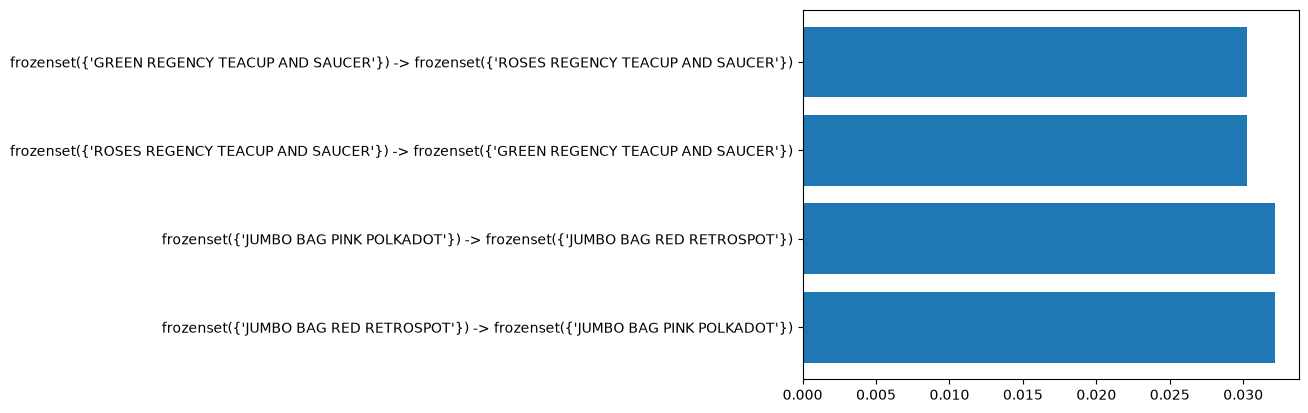

In [22]:
# visualization
top10=rules.sort_values(by='support',ascending=False).head(10)

labels=top10['antecedents'].astype(str)+' -> '+top10['consequents'].astype(str)

plt.barh(labels,top10['support'])
plt.show()

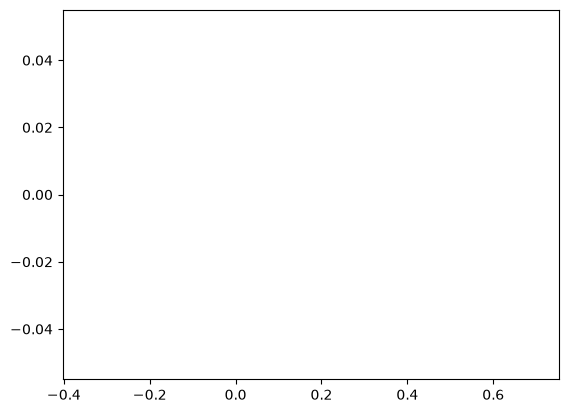

In [23]:
support_values=[0.05,0.06,0.3]
counts=[]

for val in support_values:
    count=(rules['support']>=val).sum()
    counts.append(count)

plt.bar(support_values,counts)
plt.show()